In [12]:
import pandas as pd
import mplfinance as mpf
import matplotlib.pyplot as plt

In [4]:
XAUUSD_df = pd.read_csv('COMEX_GC_data.csv')
XAUUSDT_df = pd.read_csv('binance_xauusdt_1m.csv')

# Convert timestamp to datetime
XAUUSD_df["timestamp"] = pd.to_datetime(XAUUSD_df["Datetime"])
XAUUSDT_df["timestamp"] = pd.to_datetime(XAUUSDT_df["open_time"])

# Select time interval
start = "2026-11-10 20:00"
end = "2026-11-11 9:00"

XAUUSD_filtered = XAUUSD_df[
    (XAUUSD_df["timestamp"] >= start) &
    (XAUUSD_df["timestamp"] <= end)
]

XAUUSDT_filtered = XAUUSDT_df[
    (XAUUSDT_df["timestamp"] >= start) &
    (XAUUSDT_df["timestamp"] <= end)
]

print(XAUUSD_filtered.head())
print(XAUUSDT_filtered.head())

                       Datetime        Close         High          Low  \
3198  2026-11-10 20:00:00+00:00  4035.199951  4037.600098  4034.600098   
3199  2026-11-10 20:01:00+00:00  4035.899902  4035.899902  4035.199951   
3200  2026-11-10 20:02:00+00:00  4035.500000  4036.000000  4035.399902   
3201  2026-11-10 20:03:00+00:00  4034.199951  4035.300049  4033.399902   
3202  2026-11-10 20:04:00+00:00  4035.100098  4035.100098  4034.100098   

             Open  Volume                 timestamp  
3198  4037.500000      86 2026-11-10 20:00:00+00:00  
3199  4035.199951      35 2026-11-10 20:01:00+00:00  
3200  4036.000000      21 2026-11-10 20:02:00+00:00  
3201  4035.300049      54 2026-11-10 20:03:00+00:00  
3202  4034.100098      17 2026-11-10 20:04:00+00:00  
                       open_time     open     high      low    close   volume  \
49018  2026-11-10 20:00:00+00:00  4036.15  4036.15  4033.46  4034.02  250.476   
49019  2026-11-10 20:01:00+00:00  4034.03  4034.40  4034.02  4034.40 

In [ ]:
# change the timestamp to datetime and floor to the nearest minute, 
# eliminating millisecond differences
XAUUSD_filtered["timestamp"] = pd.to_datetime(XAUUSD_filtered["timestamp"]).dt.floor("min")
XAUUSDT_filtered["timestamp"] = pd.to_datetime(XAUUSDT_filtered["timestamp"]).dt.floor("min")

# merge on timestamp, keeping only rows where both datasets have values
spread_df = pd.merge(
    XAUUSD_filtered[["timestamp", "Close"]],
    XAUUSDT_filtered[["timestamp", "close"]],
    on="timestamp",
    how="inner"
)

# calculate the spread
spread_df["spread"] = spread_df["Close"] - spread_df["close"]

print(spread_df.head())

                  timestamp        Close    close    spread
0 2026-11-10 20:00:00+00:00  4035.199951  4034.02  1.179951
1 2026-11-10 20:01:00+00:00  4035.899902  4034.40  1.499902
2 2026-11-10 20:02:00+00:00  4035.500000  4034.52  0.980000
3 2026-11-10 20:03:00+00:00  4034.199951  4033.33  0.869951
4 2026-11-10 20:04:00+00:00  4035.100098  4033.85  1.250098


                                 Close    close    spread
timestamp                                                
2026-11-10 20:00:00+00:00  4035.199951  4034.02  1.179951
2026-11-10 20:01:00+00:00  4035.899902  4034.40  1.499902
2026-11-10 20:02:00+00:00  4035.500000  4034.52  0.980000
2026-11-10 20:03:00+00:00  4034.199951  4033.33  0.869951
2026-11-10 20:04:00+00:00  4035.100098  4033.85  1.250098


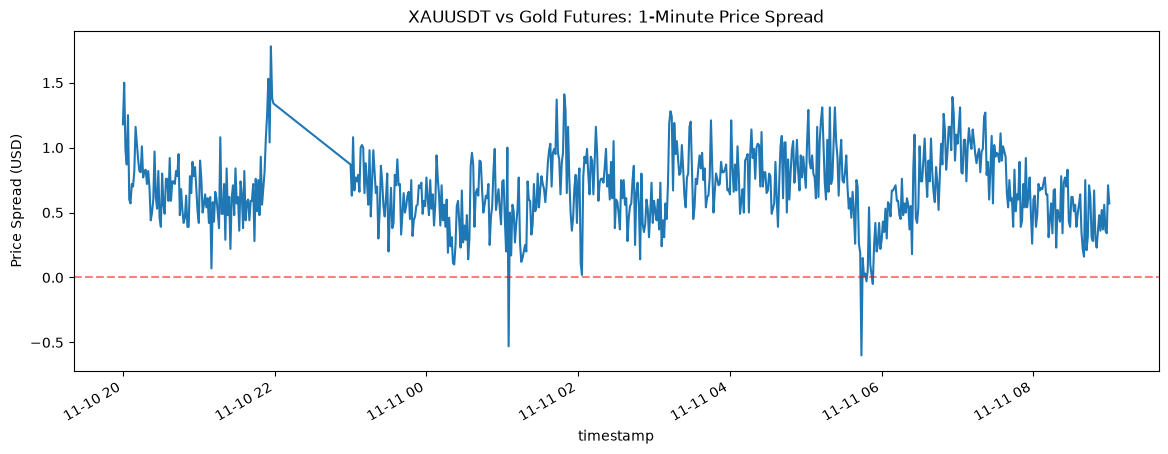

In [ ]:
print(spread_df.head())

# it only works if the timestamp is set as the index, so we reset the index first
spread_df = spread_df.reset_index()

# convert timestamp to datetime and set as index
spread_df["timestamp"] = pd.to_datetime(
    spread_df["timestamp"], utc=True
)
# if we reset everytime, we can debug and change the parameters easily
# so everytime we run the code, we reset the index and sort it again

spread_df = spread_df.set_index("timestamp").sort_index()

spread_df["spread"].tail(1000).plot(
    figsize=(14, 5),
    title="XAUUSDT vs Gold Futures: 1-Minute Price Spread",
    ylabel="Price Spread (USD)"
)

plt.axhline(0, color="red", linestyle="--", alpha=0.5)
plt.show()

In [20]:
print(spread_df["spread"].describe())

count    720.000000
mean       0.681262
std        0.277335
min       -0.600098
25%        0.500085
50%        0.679927
75%        0.849915
max        1.780098
Name: spread, dtype: float64
